# Don't Get Kicked — XGBoost_drop_imp solution

## Solution overview
Exactly the same as in `XGB_solution`, but the top 5 features are also removed in FID.





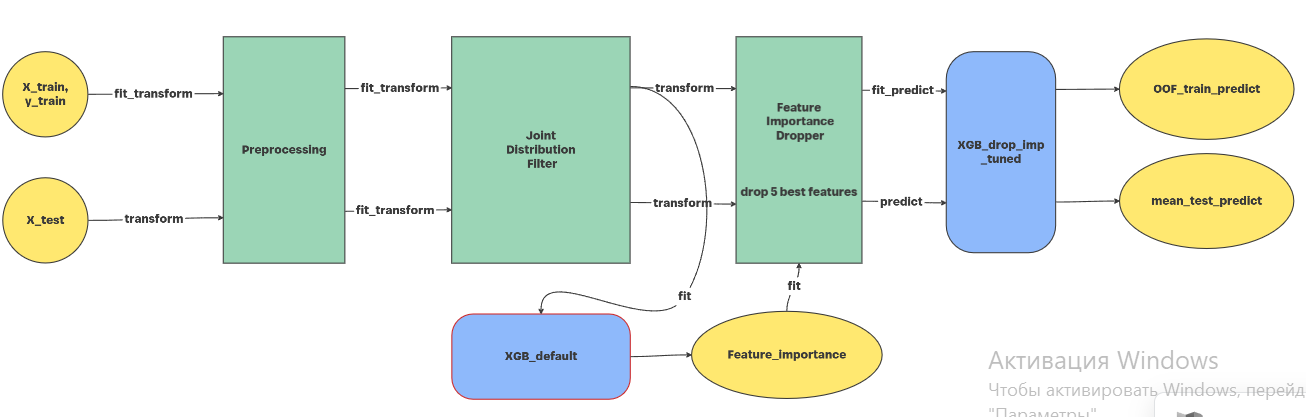


The library versions on Kaggle may differ from those on my local machine, which could lead to slight variations in the results compared to what is shown here. You can find a fully reproducible solution, including a `requirements.txt` file, on my GitHub profile.

In [6]:
# !pip install -r ../requirements.txt --quiet


In [7]:
SEED, K = 42, 5
TRAIN_PATH = "../dont_get_kicked/datasets/training.csv"
TEST_PATH = "../dont_get_kicked/datasets/test.csv"
IMPORTANCE_PATH = "../importance_df.csv"  
OUT_PATH = "xgb_drop_imp_kaggle_submission.csv"
N_ITER = 730 

CFG = {
      "rank": 0,
      "outer_trial": 0,
      "val_auc": 0.7983215975567883,
      "best_estimators": 904,
      "preprocessing": {
        "date_days": 13,
        "text_min_count_train": 435
      },
      "inner_trial": 94,
      "jdf": {
        "dp": 0.01776521157190518,
        "th_num_train": 0.010829244816237956,
        "th_num_test": 0.0013148180215723049,
        "th_cat_train": 0.0035524126232603192,
        "th_cat_test": 0.0010030811989344564
      },
      "fid": {
        "n_worst": 150
      },
      "xgb": {
        "objective": "binary:logistic",
        "learning_rate": 0.02043986587702566,
        "max_depth": 10,
        "min_child_weight": 45.505711836027224,
        "subsample": 0.9739115600237975,
        "colsample_bytree": 0.3586114583603864,
        "gamma": 0.02382195510531528,
        "reg_alpha": 0.07874092801695182,
        "reg_lambda": 0.0001462793376874774
      }
    }

## Code: preprocessing classes
see `eda.ipynb` for more details

In [8]:
import re
from collections import Counter
from typing import Optional

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

import xgboost as xgb

MMR_COLS = ['MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']
NUMER_COLS = MMR_COLS + ['WarrantyCost', 'VehBCost']
CAT_COLS = ['Auction', 'BYRNO', 'VNZIP1', 'VNST', 'VehYear', 'Make', 'Model', 'Trim', 'SubModel', 'WheelType', 'Size', 'Color', 'PRIMEUNIT']
TEXT_COLS = ['Make', 'Model', 'Trim', 'SubModel']
DEFAULT_JDF_NUM_COLS = ['WarrantyCost', 'VehBCost', 'REL_DRIFT_RET_CLEAN', 'REL_DRIFT_RET_AVG', 'REL_DRIFT_AUC_AVG', 'REL_WarrantyCost', 'REL_VehBCost', 'VehOdo', 'VEHODO/VEHICLEAGE']
DEFAULT_JDF_CAT_COLS = list(CAT_COLS)+["date_days_count"]
TOKEN_RE = re.compile('[a-z0-9]+')
PURCH_DATE_ORIGIN = pd.Timestamp('2009-01-05')

class Preprocessing(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        mmr_cols: Optional[list] = None,
        numer_cols: Optional[list] = None,
        cat_cols: Optional[list] = None,
        text_cols: Optional[list] = None,
        price_trash_threshold: float = 100.0,
        cramer_v_min: float = 0.5,
        price_pipeline_degree: int = 3,
        price_pipeline_alpha: float = 0.007,
        text_min_count_train: int = 100,
        text_logreg_C: float = 65.0,
        add_text_binary_matrix: bool = False,
        date_pipeline_degree: int = 13,
        date_pipeline_alpha: float = 0.007,
        date_days: int = 14,
        min_flag_count: int = 500,
        weekday_type:str = 'category',
    ):
        self.mmr_cols = list(mmr_cols) if mmr_cols is not None else list(MMR_COLS)
        self.numer_cols = list(numer_cols) if numer_cols is not None else list(NUMER_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(CAT_COLS)
        self.text_cols = list(text_cols) if text_cols is not None else list(TEXT_COLS)
        self.price_trash_threshold = price_trash_threshold
        self.cramer_v_min = cramer_v_min
        self.price_pipeline_degree = price_pipeline_degree
        self.price_pipeline_alpha = price_pipeline_alpha
        self.text_min_count_train = text_min_count_train
        self.text_logreg_C = text_logreg_C
        self.add_text_binary_matrix = add_text_binary_matrix
        self.date_pipeline_degree = date_pipeline_degree
        self.date_pipeline_alpha = date_pipeline_alpha
        self.date_days = date_days
        self.min_flag_count = min_flag_count
        self.weekday_type = weekday_type
        # Сохраняемые после fit атрибуты
        self.numer_cols_means = {}
        self.text_vocab = set()
        self.text_model = None
        self.text_vector_names = []
        self.price_pipeline = None
        self.date_ppl = None
        self.trash_flag_cols = []

    @staticmethod
    def _cramers_v(x, y):
        """Cramer's V для двух бинарных/категориальных векторов."""
        x = np.asarray(x)
        y = np.asarray(y)
        confusion = pd.crosstab(x, y)
        try:
            from scipy.stats import chi2_contingency

            chi2, _, _, _ = chi2_contingency(confusion.values)
        except Exception:
            chi2 = 0.0
        n = confusion.values.sum()
        phi2 = chi2 / n
        r, k = confusion.shape
        phi2corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
        rcorr = r - ((r - 1) ** 2) / (n - 1)
        kcorr = k - ((k - 1) ** 2) / (n - 1)
        denom = min((kcorr - 1), (rcorr - 1))
        if denom <= 0:
            return 0.0
        return np.sqrt(phi2corr / denom)

    @staticmethod
    def _build_text(X):
        return (
            X["Make"].fillna("").astype(str)
            + " "
            + X["Model"].fillna("").astype(str)
            + " "
            + X["Trim"].fillna("").astype(str)
            + " "
            + X["SubModel"].fillna("").astype(str)
        ).str.lower()

    @classmethod
    def _token_lists(cls, X):
        """Уникальные токены текста для каждой строки (с сохранением порядка)."""
        text = cls._build_text(X)
        return text.map(lambda s: list(dict.fromkeys(TOKEN_RE.findall(s)))).tolist()

    def _token_matrix(self, token_lists):
        """Бинарная матрица (n_rows x n_vocab, uint8) по словарю text_vector_names."""
        index = {t: j for j, t in enumerate(self.text_vector_names)}
        matrix = np.zeros((len(token_lists), len(index)), dtype=np.uint8)
        for i, toks in enumerate(token_lists):
            for t in toks:
                j = index.get(t)
                if j is not None:
                    matrix[i, j] = 1
        return matrix

    def _trash_mask(self, s):
        return (s < self.price_trash_threshold) | s.isna()

    def _clean_numeric(self, X):
        """Копия числовых колонок: мусор/NaN заменены средним по трейну."""
        X_num = X[self.numer_cols].copy().astype(float)
        for col in self.numer_cols:
            X_num.loc[self._trash_mask(X_num[col]), col] = self.numer_cols_means[col]
        return X_num

    def _date_frame(self, X):
        return pd.DataFrame(
            {"PurchDate": (X["PurchDate"] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)}
        )

    def _fill_cat_none(self, X):
        for col in self.cat_cols:
            if col in X.columns:
                X[col] = X[col].fillna("init_None").astype(str)
        return X

    def fit(self, X, y):
        X = X.copy()
        X["PurchDate"] = pd.to_datetime(X["PurchDate"])
        y_arr = y.values.astype(float) if hasattr(y, "values") else np.asarray(y, dtype=float)

        # --- 1) Чистка ценовых колонок: средние по "нормальным" значениям ---
        self.numer_cols_means = {}
        for col in self.numer_cols:
            self.numer_cols_means[col] = X.loc[~self._trash_mask(X[col]), col].mean()

        # --- 2) Флаги is_trash + отбор по Cramer's V и частоте ---
        trash_flags = {
            f"{col}_is_trash": self._trash_mask(X[col]).astype(int) for col in self.numer_cols
        }
        flag_cols = list(trash_flags.keys())
        keep_flags = list(flag_cols)
        for i, c1 in enumerate(flag_cols):
            for c2 in flag_cols[i + 1:]:
                v = self._cramers_v(trash_flags[c1], trash_flags[c2])
                if v > self.cramer_v_min:
                    if trash_flags[c1].mean() < trash_flags[c2].mean():
                        if c1 in keep_flags:
                            keep_flags.remove(c1)
                    else:
                        if c2 in keep_flags:
                            keep_flags.remove(c2)
        for c in list(keep_flags):
            if trash_flags[c].sum() < self.min_flag_count:
                keep_flags.remove(c)
        self.trash_flag_cols = keep_flags

        # --- 3) price_pipeline ---
        X_num = self._clean_numeric(X)
        self.price_pipeline = Pipeline(
            [
                ("SS1", StandardScaler()),
                ("PT", PolynomialFeatures(self.price_pipeline_degree, include_bias=False)),
                ("SS2", StandardScaler()),
                ("LR", LogisticRegression(C=100, max_iter=10000)),
            ]
        ).fit(X_num, y_arr)

        # --- 4) Date_factor ---
        self.date_ppl = Pipeline(
            [
                ("ss1", StandardScaler()),
                ("pt", PolynomialFeatures(degree=self.date_pipeline_degree, include_bias=False)),
                ("ss2", StandardScaler()),
                ("lr", Ridge(alpha=self.date_pipeline_alpha)),
            ]
        ).fit(self._date_frame(X), y_arr)

        # --- 5) Текст: словарь токенов + LogReg text_factor ---
        # None в категориальных колонках -> 'init_None' (как и в transform)
        Xp = self._fill_cat_none(X.copy())
        token_lists = self._token_lists(Xp)
        token_counts = Counter(t for toks in token_lists for t in toks)
        thr = self.text_min_count_train
        if isinstance(thr, float):
            thr = thr * len(Xp)
        self.text_vocab = {t for t, c in token_counts.items() if c >= thr}
        self.text_vector_names = sorted(self.text_vocab)

        if self.text_vector_names:
            token_matrix = self._token_matrix(token_lists)
            self.text_model = LogisticRegression(C=self.text_logreg_C, max_iter=5000)
            self.text_model.fit(token_matrix, y_arr)
        else:
            self.text_model = None

        return self

    def transform(self, X):
        X = X.copy()
        X["PurchDate"] = pd.to_datetime(X["PurchDate"])
        X = self._fill_cat_none(X)

        X_trans = self._clean_numeric(X)
        divisor = X_trans["MMRAcquisitionAuctionCleanPrice"].copy()
        X_trans["price_factor"] = self.price_pipeline.predict_proba(X_trans[self.numer_cols])[:, 1]

        # Категориальные колонки (None уже заменён на 'init_None')
        for col in self.cat_cols:
            if col in X.columns:
                X_trans[col] = X[col]

        # Бинарные флаги is_trash для ценовых колонок
        for col_base in self.numer_cols:
            flag_name = f"{col_base}_is_trash"
            if flag_name in self.trash_flag_cols:
                X_trans[flag_name] = self._trash_mask(X[col_base]).astype(int)

        # Токены текста: один раз для OHE-матрицы и text_factor
        token_matrix = None
        if self.text_vector_names:
            token_matrix = self._token_matrix(self._token_lists(X))

        # OHE-матрица текста (если флаг)
        if self.add_text_binary_matrix and token_matrix is not None:
            ohe_df = pd.DataFrame(
                token_matrix,
                columns=[f"text__{t}" for t in self.text_vector_names],
                index=X.index,
            )
            X_trans = pd.concat([X_trans, ohe_df], axis=1)

        # Feature engineering ценовых фичей
        X_trans["REL_DRIFT_RET_CLEAN"] = (
            X_trans["MMRCurrentRetailCleanPrice"] - X_trans["MMRAcquisitonRetailCleanPrice"]
        ) / X_trans["MMRAcquisitonRetailCleanPrice"]
        X_trans["REL_DRIFT_RET_AVG"] = (
            X_trans["MMRCurrentRetailAveragePrice"] - X_trans["MMRAcquisitionRetailAveragePrice"]
        ) / X_trans["MMRAcquisitionRetailAveragePrice"]
        X_trans["REL_DRIFT_AUC_AVG"] = (
            X_trans["MMRCurrentAuctionAveragePrice"] - X_trans["MMRAcquisitionAuctionAveragePrice"]
        ) / X_trans["MMRAcquisitionAuctionAveragePrice"]

        X_trans.drop(columns=self.numer_cols[: len(MMR_COLS)], inplace=True, errors="ignore")

        rel_cols = ["WarrantyCost", "VehBCost"]
        X_trans[["REL_" + col for col in rel_cols]] = (
            X_trans[rel_cols].values / divisor.values.reshape(-1, 1)
        )

        # Фичи VehOdo / VehicleAge
        X_trans[["VehOdo", "VehicleAge"]] = X[["VehOdo", "VehicleAge"]]
        X_trans["VEHODO/VEHICLEAGE"] = X["VehOdo"] / (X["VehicleAge"] + 1)

        # Текстовый фактор (LogReg на бинарной матрице токенов)
        if self.text_model is not None and token_matrix is not None:
            X_trans["text_factor"] = self.text_model.predict_proba(token_matrix)[:, 1]

        # Дата
        X_trans["Date_factor"] = self.date_ppl.predict(self._date_frame(X))
        X_trans["date_days_count"] = (
            (X["PurchDate"] - PURCH_DATE_ORIGIN) // pd.Timedelta(days=self.date_days)
        ).astype(self.weekday_type)

        for col in self.cat_cols:
            if col in X_trans.columns:
                X_trans[col] = X_trans[col].astype("category")

        return X_trans

    def fit_transform(self, X, y=None, **fit_params):
        self.fit(X, y)
        return self.transform(X)

class JointDistributionFilter(TransformerMixin):

    def __init__(self, X_train, X_test=None, num_cols=None, cat_cols=None, dp: float=0.02, th_num_train: float=0.001, th_num_test: float=0.001, th_cat_train: float=0.005, th_cat_test: float=0.005, min_dx_frac: float=0.001, bin_prefix: str='text__', verbose: bool=False):
        self.dp = dp
        self.th_num_train = th_num_train
        self.th_num_test = th_num_test
        self.th_cat_train = th_cat_train
        self.th_cat_test = th_cat_test
        self.min_dx_frac = min_dx_frac
        self.bin_prefix = bin_prefix
        self.verbose = verbose
        self.num_cols = list(num_cols) if num_cols is not None else list(DEFAULT_JDF_NUM_COLS)
        self.cat_cols = list(cat_cols) if cat_cols is not None else list(DEFAULT_JDF_CAT_COLS)
        self.train_profiles = {}
        self.test_profiles = {}
        self.bin_train_freq = {}
        self.bin_test_freq = {}
        self.bin_cols_to_drop_ = []
        self._build_profiles(X_train, is_test=False)
        if X_test is not None:
            self._build_profiles(X_test, is_test=True)
        self._build_bin_freqs(X_train, X_test)

    def _num_profile(self, s):
        x = pd.to_numeric(s, errors='coerce').dropna()
        n = len(x)
        if n == 0:
            return None
        shares = x.value_counts(normalize=True)
        heavy = shares[shares >= self.dp]
        heavy_shares = heavy.to_dict()
        rest = x[~x.isin(heavy.index)].values
        profile = {'heavy': heavy_shares, 'cx': None, 'log_cy': None}
        if len(rest) < 2:
            return profile
        rng = rest.max() - rest.min()
        if rng <= 0:
            return profile
        n_bins = int(round(1 / self.dp))
        edges = np.quantile(rest, np.linspace(0, 1, n_bins + 1))
        dx = np.maximum(np.diff(edges), self.min_dx_frac * rng)
        dens = 1.0 / n_bins / dx * rng
        centers = (edges[:-1] + edges[1:]) / 2.0
        cx = np.concatenate([[edges[0]], centers, [edges[-1]]])
        cy = np.concatenate([[dens[0]], dens, [dens[-1]]])
        profile['cx'], profile['log_cy'] = (cx, np.log(cy))
        return profile

    def _build_profiles(self, df, is_test: bool=False):
        profiles = {}
        for col in self.num_cols:
            if col in df.columns:
                p = self._num_profile(df[col])
                if p is not None:
                    profiles[col] = p
        for col in self.cat_cols:
            if col in df.columns:
                profiles[col] = df[col].value_counts(normalize=True).to_dict()
        if is_test:
            self.test_profiles = profiles
        else:
            self.train_profiles = profiles

    def _build_bin_freqs(self, X_train, X_test=None):
        bin_cols = [c for c in X_train.columns if str(c).startswith(self.bin_prefix)]
        self.bin_train_freq = {c: float(pd.to_numeric(X_train[c], errors='coerce').fillna(0).mean()) for c in bin_cols}
        self.bin_test_freq = {}
        if X_test is not None:
            self.bin_test_freq = {c: float(pd.to_numeric(X_test[c], errors='coerce').fillna(0).mean()) for c in bin_cols if c in X_test.columns}
        drop = []
        for c in bin_cols:
            if self.bin_train_freq[c] < self.th_cat_train:
                drop.append(c)
            elif X_test is not None and self.bin_test_freq.get(c, 0.0) < self.th_cat_test:
                drop.append(c)
        self.bin_cols_to_drop_ = drop
        if self.verbose:
            print(f'binary {self.bin_prefix}* columns: dropping {len(drop)} of {len(bin_cols)}')

    @staticmethod
    def _num_pass_mask(x, profile, th_num, th_heavy):
        if profile['cx'] is None:
            mask = np.zeros(len(x), dtype=bool)
        else:
            log_d = np.interp(x, profile['cx'], profile['log_cy'], left=-np.inf, right=-np.inf)
            mask = np.exp(log_d) >= th_num
        if profile['heavy']:
            share = pd.Series(x).map(profile['heavy']).values
            is_heavy = ~np.isnan(share)
            mask = np.where(is_heavy, np.nan_to_num(share) >= th_heavy, mask)
        return mask

    @staticmethod
    def _cat_share(values, profile):
        s = pd.Series(np.asarray(values, dtype=object))
        return s.map(profile).astype(float).fillna(0.0).values

    def _surviving_categories(self, col):
        cats = []
        test_profile = self.test_profiles.get(col)
        for k, share in self.train_profiles[col].items():
            if share < self.th_cat_train or share <= 0:
                continue
            if test_profile is not None and test_profile.get(k, 0.0) < self.th_cat_test:
                continue
            cats.append(k)
        return cats

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()
        for col in self.num_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            x = pd.to_numeric(X_out[col], errors='coerce').astype(float).values
            final = self._num_pass_mask(x, self.train_profiles[col], self.th_num_train, self.th_cat_train)
            if col in self.test_profiles:
                final &= self._num_pass_mask(x, self.test_profiles[col], self.th_num_test, self.th_cat_test)
            was_nan = np.isnan(x)
            out = x.copy()
            out[~final] = np.nan
            X_out[col] = out
            if self.verbose:
                print(f'{col}: masked {(~final & ~was_nan).mean():.2%} of values')
        for col in self.cat_cols:
            if col not in X_out.columns or col not in self.train_profiles:
                continue
            vals = X_out[col].values
            final = self._cat_share(vals, self.train_profiles[col]) >= self.th_cat_train
            if col in self.test_profiles:
                final &= self._cat_share(vals, self.test_profiles[col]) >= self.th_cat_test
            cats = self._surviving_categories(col)
            X_out[col] = pd.Series(np.asarray(X_out[col].values, dtype=object), index=X_out.index).where(final).astype(pd.CategoricalDtype(categories=cats))
            if self.verbose:
                print(f'{col}: masked {(~final).mean():.2%} of values')
        drop_cols = [c for c in self.bin_cols_to_drop_ if c in X_out.columns]
        if drop_cols:
            X_out = X_out.drop(columns=drop_cols)
        return X_out

class FeatureImportanceDropper(BaseEstimator, TransformerMixin):

    def __init__(self, importance_path: str='D:/DS_Proj/importance_df.csv', n_worst: int=170, n_best=None):
        self.importance_path = importance_path
        self.n_worst = n_worst
        self.n_best = n_best

    def fit(self, X: pd.DataFrame, y=None):
        imp = pd.read_csv(self.importance_path)
        imp = imp.loc[:, ['Feature', 'Importance']]
        imp = imp.sort_values('Importance', ascending=True).reset_index(drop=True)
        self.features_to_drop_ = imp['Feature'].iloc[:self.n_worst].tolist() + (imp['Feature'].iloc[-self.n_best:].tolist() if self.n_best else [])
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        cols = [c for c in self.features_to_drop_ if c in X.columns]
        return X.drop(columns=cols)

## Data

In [9]:
train, test = pd.read_csv(TRAIN_PATH), pd.read_csv(TEST_PATH)
train["PurchDate"], test["PurchDate"] = pd.to_datetime(train["PurchDate"]), pd.to_datetime(test["PurchDate"])
y = train["IsBadBuy"]
X, X_test, ref_id = train.drop(columns=["IsBadBuy", "RefId"]), test.drop(columns=["RefId"]), test["RefId"]
folds = list(StratifiedKFold(K, shuffle=True, random_state=SEED).split(X, y))
print(X.shape, X_test.shape, "positive rate:", round(y.mean(), 4))

(72983, 32) (48707, 32) positive rate: 0.123


## Training: 5 folds, pipeline fitted inside every fold, averaged test predictions

In [10]:
def drop_empty_cats(*frames):
    """Drop categorical columns left without any category after the JDF (all values became NaN)."""
    empty = [c for c in frames[0] if isinstance(frames[0][c].dtype, pd.CategoricalDtype) and len(frames[0][c].cat.categories) == 0]
    return [f.drop(columns=empty) for f in frames]

oof, test_pred = np.zeros(len(X)), np.zeros(len(X_test))
for k, (tr, va) in enumerate(folds):
    prep = Preprocessing(add_text_binary_matrix=True, **CFG["preprocessing"]).fit(X.iloc[tr], y.iloc[tr])
    Xtr, Xva, Xte = (prep.transform(d) for d in (X.iloc[tr], X.iloc[va], X_test))
    jdf = JointDistributionFilter(Xtr, Xte, **CFG["jdf"])
    Xtr, Xva, Xte = drop_empty_cats(*(jdf.transform(d) for d in (Xtr, Xva, Xte)))
    fid = FeatureImportanceDropper(IMPORTANCE_PATH, n_best = 5, **CFG["fid"]).fit(Xtr)
    Xtr, Xva, Xte = (fid.transform(d) for d in (Xtr, Xva, Xte))
    model = xgb.XGBClassifier(n_estimators=N_ITER, tree_method="hist", enable_categorical=True,
                              eval_metric="auc", random_state=SEED, **CFG["xgb"]).fit(Xtr, y.iloc[tr])
    oof[va] = model.predict_proba(Xva)[:, 1]
    test_pred += model.predict_proba(Xte)[:, 1] / K
    print(f"fold {k}: features={Xtr.shape[1]}, val AUC={roc_auc_score(y.iloc[va], oof[va]):.5f}")

fold 0: features=92, val AUC=0.76018
fold 1: features=91, val AUC=0.75090
fold 2: features=91, val AUC=0.76263
fold 3: features=91, val AUC=0.75855
fold 4: features=91, val AUC=0.75562


## Submission

In [11]:
print("OOF ROC AUC:", round(roc_auc_score(y, oof), 5))
pd.DataFrame({"RefId": ref_id, "IsBadBuy": test_pred}).to_csv(OUT_PATH, index=False)
print("saved", OUT_PATH)

OOF ROC AUC: 0.75753
saved xgb_drop_imp_kaggle_submission.csv


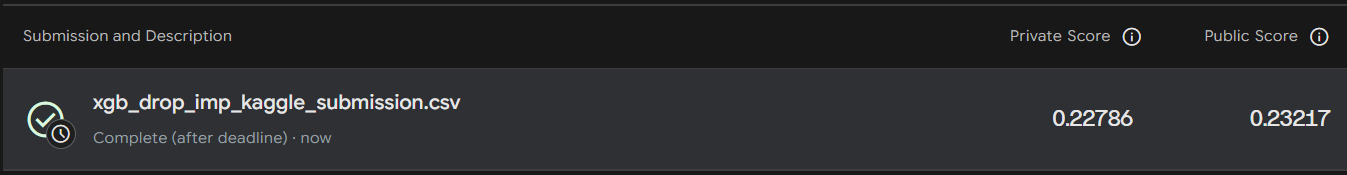